# Step 00: Dataset Ingestion & 3-Fold Leave-One-Subject-Out (LOSO) Partitioning

Audits all 102 CSV recording files from the TI IWR6843 mmWave Radar Fall Detection Dataset,
verifies the 51 Fall / 51 Non-Fall (ADL) class balance across 3 subjects (`Areeb`, `Raffay`, `Towsif`),
and constructs clean, zero-leakage **3-Fold Leave-One-Subject-Out (LOSO)** data partitions (68 Train files / 34 Test files per fold).


In [1]:
# Cell 1: System Imports & Path Setup
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.dataset_parser import get_all_recording_files, extract_subject, extract_label, get_loso_splits

sns.set_theme(style="whitegrid")
print("System ready for dataset auditing.")


System ready for dataset auditing.


In [2]:
# Cell 2: Discover and Audit All 102 CSV Files
all_files = get_all_recording_files()
print(f"Total TI CSV Files Discovered: {len(all_files)}")

fall_files = [f for f in all_files if extract_label(f) == 1]
not_files = [f for f in all_files if extract_label(f) == 0]
print(f"  - Fall Recordings (Class 1): {len(fall_files)}")
print(f"  - ADL Recordings (Class 0):  {len(not_files)}")

subjects = sorted(list({extract_subject(f) for f in all_files}))
print(f"\nSubject Breakdown across {len(subjects)} Subjects:")
subj_data = []
for s in subjects:
    s_falls = sum(1 for f in fall_files if extract_subject(f) == s)
    s_adls = sum(1 for f in not_files if extract_subject(f) == s)
    subj_data.append({"Subject": s, "Total Files": s_falls + s_adls, "Falls (1)": s_falls, "ADLs (0)": s_adls})
df_subj = pd.DataFrame(subj_data)
print(df_subj.to_string(index=False))


Total TI CSV Files Discovered: 102
  - Fall Recordings (Class 1): 51
  - ADL Recordings (Class 0):  51

Subject Breakdown across 3 Subjects:
Subject  Total Files  Falls (1)  ADLs (0)
  Areeb           34         17        17
 Raffay           34         17        17
 Towsif           34         17        17


In [3]:
# Cell 3: Construct and Verify 3-Fold LOSO Data Splits
splits = get_loso_splits()
split_records = []
for f_info in splits:
    tr_falls = sum(1 for f in f_info["train_files"] if extract_label(f) == 1)
    tr_adls = sum(1 for f in f_info["train_files"] if extract_label(f) == 0)
    te_falls = sum(1 for f in f_info["test_files"] if extract_label(f) == 1)
    te_adls = sum(1 for f in f_info["test_files"] if extract_label(f) == 0)
    
    split_records.append({
        "Fold": f_info["fold"],
        "Test Subject": f_info["test_subject"],
        "Train Subjects": ", ".join(f_info["train_subjects"]),
        "Train Total": len(f_info["train_files"]),
        "Train Falls": tr_falls,
        "Train ADLs": tr_adls,
        "Test Total": len(f_info["test_files"]),
        "Test Falls": te_falls,
        "Test ADLs": te_adls
    })

df_splits = pd.DataFrame(split_records)
print("\n--- 3-Fold Leave-One-Subject-Out (LOSO) Split Summary ---")
print(df_splits.to_string(index=False))



--- 3-Fold Leave-One-Subject-Out (LOSO) Split Summary ---
 Fold Test Subject Train Subjects  Train Total  Train Falls  Train ADLs  Test Total  Test Falls  Test ADLs
    0        Areeb Raffay, Towsif           68           34          34          34          17         17
    1       Raffay  Areeb, Towsif           68           34          34          34          17         17
    2       Towsif  Areeb, Raffay           68           34          34          34          17         17


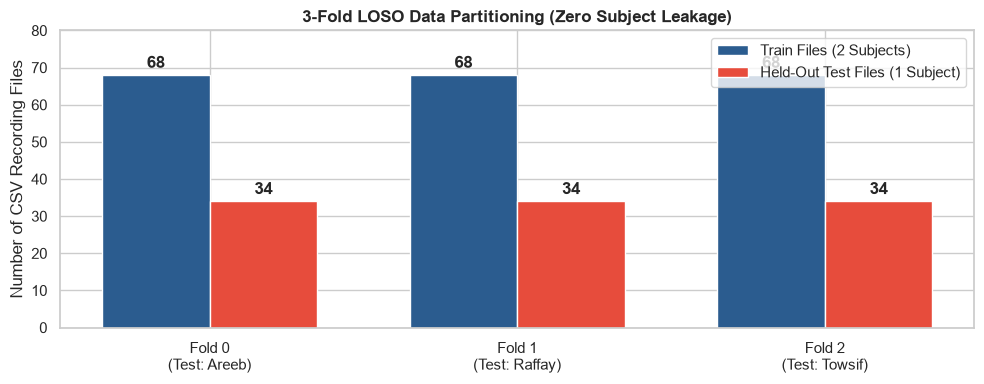

In [4]:
# Cell 4: Visualize Fold Class Distribution & Subject Isolation
fig, ax = plt.subplots(figsize=(10, 4), dpi=100)
x_vals = np.arange(len(splits))
width = 0.35

tr_counts = df_splits["Train Total"]
te_counts = df_splits["Test Total"]

ax.bar(x_vals - width/2, tr_counts, width, label="Train Files (2 Subjects)", color="#2b5c8f")
ax.bar(x_vals + width/2, te_counts, width, label="Held-Out Test Files (1 Subject)", color="#e74c3c")

ax.set_xticks(x_vals)
ax.set_xticklabels([f"Fold {row['Fold']}\n(Test: {row['Test Subject']})" for _, row in df_splits.iterrows()])
ax.set_ylabel("Number of CSV Recording Files")
ax.set_title("3-Fold LOSO Data Partitioning (Zero Subject Leakage)", fontweight="bold")
ax.legend()
ax.set_ylim(0, 80)

for bar in ax.patches:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h + 1, f"{int(h)}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()
